# CIFAR-10: second submission

**Zihan Xu**

The submitted model achieved **87.90% public accuracy** with **2,436,346 trainable parameters**. Its private score is not recorded. The **96.04% research validation mean** comes from three models trained on 40,000 images. The final submitted model used all 50,000 labeled images and has no independent local holdout.

This notebook checks the saved model and evidence, recomputes validation results, and displays the training record. Run it from the repository root.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from verify import audit, read, digest

TASK = Path.cwd()
assert (TASK / 'config.json').exists(), 'Run from the directory containing this notebook'
plt.rcParams.update({'font.size':10, 'axes.spines.top':False, 'axes.spines.right':False})
checks = audit(TASK)
print('Final Kaggle PUBLIC accuracy: 87.90% (0.87900)')
print('Final trainable parameters:', format(checks['parameters'], ','))
print('Private Kaggle accuracy: not recorded')
print('Final independent local accuracy: unavailable after the full-50k fit')
print('Verified research runs:', checks['completed_research_runs'])
print('Verified raw/TTA prediction tables:', checks['research_prediction_tables_verified'])
print('Final training:', checks['final_training_epochs'], 'epochs;', checks['optimizer_updates'], 'optimizer updates')
history = pd.read_csv(TASK/'evidence/history.csv')
summary = pd.read_csv(TASK/'evidence/confirmation_inference_summary.csv')
metrics = pd.read_csv(TASK/'evidence/confirmation_inference_run_metrics.csv')


Final Kaggle PUBLIC accuracy: 87.90% (0.87900)
Final trainable parameters: 2,436,346
Private Kaggle accuracy: not recorded
Final independent local accuracy: unavailable after the full-50k fit
Verified research runs: 30
Verified raw/TTA prediction tables: 60
Final training: 240 epochs; 93840 optimizer updates


## Confirmation results

The study completed ten configurations with seeds 142, 143 and 144. Every run used the same 5,000 validation images. Raw and horizontal-flip test-time augmentation (TTA) were evaluated at the same checkpoint, selected by raw validation accuracy. Error bars show standard deviation across seeds. None of the 34 planned comparisons passed Holm correction at 0.05.

In [2]:
display(summary.pivot(index='configuration', columns='policy', values='mean_accuracy_percent').round(4))
display(metrics[metrics.configuration.eq('long_111')][['configuration','seed','policy','validation_correct']])
print('Selected research TTA mean:', checks['research_validation_mean_percent'], '%')


policy,raw,tta
configuration,,
confirm_000,94.8267,95.2333
confirm_001,95.0467,95.3867
confirm_010,95.0800,95.2400
confirm_011,94.9267,95.2667
confirm_100,95.1733,95.5267
confirm_101,95.3133,95.5333
confirm_110,95.2333,95.4667
confirm_111,95.4400,95.6600
long_000,95.4267,95.7333


,configuration,seed,policy,validation_correct
18,long_111,142,raw,4796
19,long_111,142,tta,4803
38,long_111,143,raw,4801
39,long_111,143,tta,4794
58,long_111,144,raw,4798
59,long_111,144,tta,4809


Selected research TTA mean: 96.04 %


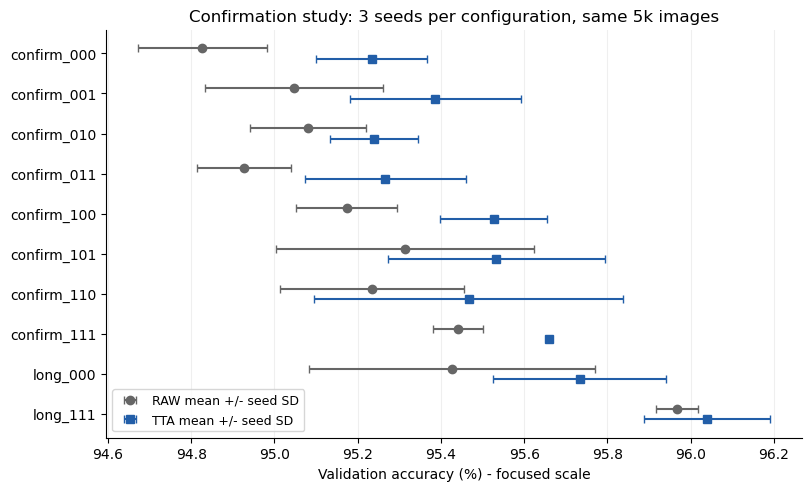

In [3]:
fig,ax=plt.subplots(figsize=(8,4.8),layout='constrained')
names=summary.configuration.drop_duplicates().tolist();y=np.arange(len(names))
for policy,offset,color,marker in [('raw',-.13,'#666666','o'),('tta',.13,'#225EA8','s')]:
    data=summary[summary.policy==policy].set_index('configuration').loc[names]
    ax.errorbar(data.mean_accuracy_percent,y+offset,xerr=data.sd_accuracy_pp,fmt=marker,color=color,capsize=3,label=policy.upper()+' mean +/- seed SD')
ax.set_yticks(y,names);ax.set_xlabel('Validation accuracy (%) - focused scale')
ax.set_title('Confirmation study: 3 seeds per configuration, same 5k images')
ax.invert_yaxis();ax.grid(axis='x',alpha=.2);ax.legend(loc='lower left',fontsize=9)
display(fig)
plt.close(fig)


Last epoch augmented training accuracy: 99.274% (NOT independent test accuracy)


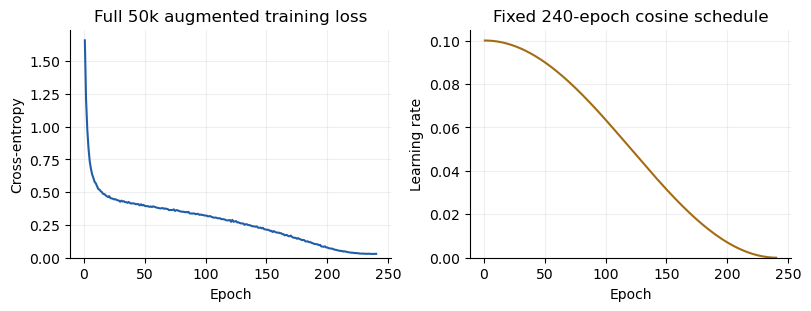

In [4]:
fig,axes=plt.subplots(1,2,figsize=(8,3),layout='constrained')
axes[0].plot(history.epoch,history.train_loss,color='#225EA8')
axes[0].set(xlabel='Epoch',ylabel='Cross-entropy',
            title='Full 50k augmented training loss',ylim=(0,None))
axes[1].plot(history.epoch,history.lr,color='#A36C14')
axes[1].set(xlabel='Epoch',ylabel='Learning rate',
            title='Fixed 240-epoch cosine schedule',ylim=(0,None))
for ax in axes:ax.grid(alpha=.2)
print('Last epoch augmented training accuracy:',f'{history.train_accuracy.iloc[-1]*100:.3f}%','(NOT independent test accuracy)')
display(fig)
plt.close(fig)


## Submitted files and reproduction checks

The recommended CSV matches the file downloaded from the second Kaggle submission. Both CSV versions use the same full-data checkpoint; the raw alternative has no recorded Kaggle score. The audit checks their hashes, IDs, labels and ordering. The saved CPU replay records reproduced all predictions, and the code-equivalence records cover initialization, forward/backward results, augmentation and the first training epoch. The cell below checks those recorded results.

In [5]:
versions = read(TASK/'submissions/versions.json')
display(pd.DataFrame(versions)[['version','configuration','training_images','policy','kaggle_score']])
print('TTA versus raw disagreements:', checks['tta_raw_disagreements'], '/ 2000')
print('Submitted CSV SHA-256:', versions[0]['submission_sha256'])
for name in ['clean_code_equivalence.json', 'clean_epoch1_replay.json', 'clean_prediction_tta.json', 'clean_prediction_raw.json']:
    result = read(TASK/'evidence'/name)
    assert result['passed']
    print(name, ': PASS')
print('No new 240-epoch fit was performed during cleanup.')


,version,configuration,training_images,policy,kaggle_score
0,01_RECOMMENDED_full50k_tta,long_111,50000,tta,0.879
1,02_ALTERNATIVE_full50k_raw,long_111,50000,raw,NaN


TTA versus raw disagreements: 69 / 2000
Submitted CSV SHA-256: f25fd0618bf2784593ca29a875839eb6e08160a58db66adf7f9c02afc5c31996
clean_code_equivalence.json : PASS
clean_epoch1_replay.json : PASS
clean_prediction_tta.json : PASS
clean_prediction_raw.json : PASS
No new 240-epoch fit was performed during cleanup.


## Development studies

The earlier studies used their own matched controls. Architecture has 42 runs; data has 71 results, including six verified historical imports; training has 120 outputs from 107 trajectories; combinations has 86 runs. Their different protocols prevent a direct comparison across stages.

The following cell checks current source hashes and independently recomputes every summary mean and sample standard deviation from per-seed correct counts. English editions of historical text are identified in [documentation_revision.json](evidence/documentation_revision.json); their numeric results are unchanged.

In [6]:
import csv
import math
import statistics

development = TASK / 'evidence/development'
for name, source in read(development / 'sources.json').items():
    assert digest(development / name) == source['sha256'], name

def records(path):
    with path.open(encoding='utf-8-sig', newline='') as file:
        return list(csv.DictReader(file))

studies = [
    ('architecture', 'configuration', 'accuracy_mean_pct', 'accuracy_sd_pp', 42),
    ('data', 'arm', 'mean', 'sd', 71),
    ('training', 'config_id', 'mean', 'sd', 120),
    ('combination', 'configuration', 'mean_accuracy_percent', 'sd_accuracy_pp', 86),
]
for study, key, mean_key, sd_key, expected in studies:
    runs = records(development / f'{study}_runs.csv')
    aggregate = records(development / f'{study}_summary.csv')
    assert len(runs) == expected
    assert len({(row[key], row['seed']) for row in runs}) == expected
    assert read(development / f'{study}_acceptance.json')['passed']
    for row in aggregate:
        values = [int(run['validation_correct']) / 50 for run in runs if run[key] == row[key]]
        assert len(values) == int(row['n']) == int(row['planned_n'])
        assert math.isclose(statistics.mean(values), float(row[mean_key]), abs_tol=1e-9)
        assert math.isclose(statistics.stdev(values), float(row[sd_key]), abs_tol=1e-9)
    print(f'{study}: {expected} results, {len(aggregate)} configurations, all summary values verified')
    display(pd.DataFrame(aggregate)[[key, 'n', mean_key, sd_key]])
assert read(development / 'training_acceptance.json')['physical_trajectories'] == 107
assert read(development / 'data_acceptance.json')['new_training_runs'] == 65
print('All 22 source records matched their recorded SHA-256 values.')


architecture: 42 results, 12 configurations, all summary values verified


,configuration,n,accuracy_mean_pct,accuracy_sd_pp
0,baseline,5,90.056,0.287888867447146
1,depth32,3,89.35333333333332,0.38279672586548713
2,equal32,3,90.26,0.24331050121192127
3,equal44,3,89.34,1.0569768209379018
4,early,3,90.34,0.28844410203711496
5,late,3,90.18666666666667,0.11547005383791858
6,preact,5,90.428,0.15786069808537415
7,se8,5,90.496,0.3606660505231928
8,eca3,3,90.38,0.37040518354903995
9,group4,3,90.18666666666667,0.2802379940931172


data: 71 results, 21 configurations, all summary values verified


,arm,n,mean,sd
0,A,5,90.328,0.24883729623993078
1,B,3,85.57333333333334,0.1814754345175508
2,C,3,78.90666666666668,0.20033305601755896
3,D,3,90.26666666666667,0.2802379940931101
4,E,3,90.02,0.12489995996796473
5,F,3,90.02666666666666,0.23007245235649545
6,G,5,89.684,0.2916847613434761
7,B_tone,3,85.64666666666666,0.4437717130838036
8,B_saturation,3,86.28000000000002,0.37363083384538637
9,B_brightness,3,86.46,0.282134719593319


training: 120 results, 34 configurations, all summary values verified


,config_id,n,mean,sd
0,base,5,90.34400000000001,0.41264997273718945
1,epochs160,3,91.08666666666666,0.37004504230340846
2,epochs240,3,91.61333333333334,0.120554275466831
3,lr005,3,89.28666666666668,0.3407834111768585
4,lr02,3,90.22000000000001,0.6502307282803539
5,warmup5,3,90.75333333333333,0.19425069712445098
6,multistep,3,90.16000000000001,0.1907878402833966
7,sgdr,3,89.96,0.4161730409336954
8,wd0003,3,91.64666666666666,0.4657610259922222
9,wd0005,5,92.24,0.3690528417449188


combination: 86 results, 22 configurations, all summary values verified


,configuration,n,mean_accuracy_percent,sd_accuracy_pp
0,core_000,5,90.34,0.413037528561267
1,core_001,5,92.22800000000001,0.3702971779530596
2,core_010,5,91.72,0.33763886032268153
3,core_011,5,93.268,0.3721827508093326
4,core_100,5,92.65599999999999,0.4045738498716873
5,core_101,5,94.16400000000002,0.12116104984688691
6,core_110,5,93.556,0.22423202269078416
7,core_111,5,94.64800000000001,0.2304777646542092
8,core_wd3,3,94.58666666666666,0.17009801096230945
9,core_cut8,3,94.62666666666667,0.1101514109457212


All 22 source records matched their recorded SHA-256 values.


## Interpretation and sources

The public score improved from 85.00% to 87.90% between the first and second submissions. Regularization, data quantity and inference changed together, so the improvement cannot be attributed to one method. The validation/public gap remains unexplained because hidden competition labels are unavailable.

See the [report](report.pdf), [references](REFERENCES.md), [evidence guide](evidence/README.md) and [reproduction commands](README.md) for the full methods and result definitions.